# Warfarin QML — Classical Learning Curve (E03/E04/E05, PCA k=4)

**Mục đích:** Thực nghiệm Learning Curve Classical tại **25% / 50% / 100% training base**, dùng LR / SVM-RBF / MLP theo cấu hình *matched-input* E01 đã có. Đây là **nhánh Classical** của E03–E05; Quantum Kernel và VQC learning curve **chưa được làm** trong notebook này.

### Thiết kế theo Guide v4 và `docs/experiment_matrix.csv`

- Quantum development pool 600 mẫu được GĐ4 khóa. Tạo **3 Stratified Holdout repeats** riêng *bên trong pool này*, mỗi repeat 480 training base + **120 validation cố định**. Đây **không phải** 3 CV folds của E01 và không sửa E01 fold IDs.
- Các mức training subset **lồng nhau**: 120 (25%) ⊂ 240 (50%) ⊂ 480 (100%). Validation 120 giữ nguyên ở cả ba mức **trong từng repeat**. Bộ mẫu giống hệt cho LR, SVM, MLP.
- **Class-count safeguard:** 120 training subset và 120 validation phải có ít nhất **10 mẫu ở từng lớp**; nếu không đạt, dừng để điều chỉnh protocol **trước khi xem model scores**, không tự oversample.
- Preprocessing → PCA k=4 → MinMaxScaler [0, π] + clip: *fit riêng trên training subset tại mỗi mức*. Không áp dụng preprocessing được fit trên 480 vào subset 120. Model configs **giữ đúng như E01 unweighted**. Nhãn được mã hóa số nội bộ theo thứ tự alphabet (High=0, Intermediate=1, Low=2) để tương thích các bản scikit-learn khi MLP dùng `early_stopping`; sau dự đoán chuyển lại nhãn chữ trước khi tính metrics.
- **Seed repeats = (7, 42, 123)** là lựa chọn được cố định trong notebook này nhưng **sau khi đã có kết quả E01**. Không trình bày là preregistered; ghi `EXPLORATORY_POST_BASELINE_HOLDOUT_SEEDS`. Không đổi seed/metric/training size dựa trên accuracy.
- Chỉ dùng Development, **Final Test tuyệt đối không dùng huấn luyện/tuning/đánh giá**. `final_split.csv` chỉ được đọc để kiểm tra ID tách biệt.
- Metric mỗi repeat và điểm learning curve: Macro-F1, Accuracy, Balanced Accuracy, Recall High, runtime. Bảng mean±sample SD là **qua 3 holdout repeats**, không phải 5-fold CV mean±SD; không trộn hai thống kê.

**Cách chạy:** Đặt notebook vào `notebooks/` của project, mở VS Code kernel `nt409`. Chạy Cell 1–3 để preflight; nếu PASS mới chạy các cell train và lưu. Không tạo script trong `scripts/`, không ghi đè file trong `docs/results/`.

## Cell 1 — Imports, project root, file outputs, chống ghi đè

In [1]:
from pathlib import Path
from time import perf_counter
from hashlib import sha256
from importlib.metadata import version
import sys
import json

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             recall_score, confusion_matrix)


def find_root(start):
    for p in (start.resolve(), *start.resolve().parents):
        if (p / "data/splits/split_manifest.json").is_file() and (p / "configs/feature_policy.yaml").is_file():
            return p
    raise FileNotFoundError("Mở project Warfarin từ VS Code workspace (hoặc thư mục notebooks của project)")

ROOT = find_root(Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.prepare_stage4 import load_and_validate_dataset, verify_raw_file
from src.preprocessing import build_preprocessor

OUT = ROOT / "docs/results"
SPLITS = ROOT / "data/splits"
CLASSES = ("Low", "Intermediate", "High")
REPEAT_SEEDS = (7, 42, 123)  # documented post-baseline, not retrospectively preregistered
FRACTIONS = (0.25, 0.50, 1.00)
MODEL_NAMES = ("LR", "SVM", "MLP")
# Stable numeric target IDs avoid a scikit-learn MLP early-stopping bug with string labels.
# Alphabetical class order mirrors scikit-learn LabelBinarizer on string labels.
NUMERIC_LABELS = tuple(sorted(CLASSES))
CLASS_TO_INT = {cls: i for i, cls in enumerate(NUMERIC_LABELS)}
INT_TO_CLASS = {i: cls for i, cls in enumerate(NUMERIC_LABELS)}
PREFIX = "classical_learning_curve_k4"
FILES = {
    "metrics": OUT / f"{PREFIX}_metrics.csv",
    "predictions": OUT / f"{PREFIX}_predictions.csv",
    "split_ids": OUT / f"{PREFIX}_split_ids.csv",
    "summary": OUT / f"{PREFIX}_summary.csv",
    "config": OUT / f"{PREFIX}_config.json",
    "figure": OUT / f"{PREFIX}_macro_f1.png",
}
assert len(set(REPEAT_SEEDS)) == 3 and len(set(FRACTIONS)) == 3
existing = [str(p) for p in FILES.values() if p.exists()]
if existing:
    raise FileExistsError("Refusing to overwrite existing learning-curve artifacts:\n" + "\n".join(existing))
print("[PASS] Environment:", sys.executable)
print("[PASS] Project:", ROOT)
print("[PASS] Outputs are available (no collision)")
print("[INFO] E03–E05 Classical-only learning curve; seeds fixed for this exploratory run")

[PASS] Environment: c:\Users\admin\anaconda3\envs\nt409\python.exe
[PASS] Project: D:\Warfarin-Quantum-Machine-Learning-Classification
[PASS] Outputs are available (no collision)
[INFO] E03–E05 Classical-only learning curve; seeds fixed for this exploratory run


## Cell 2 — Kiểm tra dữ liệu GĐ4, checksum, nhãn, Final Test isolation và experiment matrix

In [2]:
def sha256_file(path):
    hasher = sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            hasher.update(chunk)
    return hasher.hexdigest()

verify_raw_file()
policy_path = ROOT / "configs/feature_policy.yaml"
policy = yaml.safe_load(policy_path.read_text(encoding="utf-8"))
approved = list(policy["approved_X_columns"])
assert policy["training_allowed"] is True and len(set(approved)) == 10

manifest_path = SPLITS / "split_manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
assert manifest["status"] == "LOCKED_BEFORE_MODEL_PERFORMANCE"
assert manifest["quantum_dev_pool_size"] == 600 and manifest["n_splits"] == 5
assert manifest["approved_features"] == approved
for filename, expected_hash in manifest["files"].items():
    assert sha256_file(SPLITS / filename) == expected_hash, f"Split checksum mismatch: {filename}"

matrix = pd.read_csv(ROOT / "docs/experiment_matrix.csv")
for exp_id, pct in (("E03", "25%_train_base"),
                    ("E04", "50%_train_base"),
                    ("E05", "100%_train_base")):
    row = matrix.loc[matrix["experiment_id"] == exp_id]
    assert len(row) == 1
    item = row.iloc[0]
    assert item["training_pool"] == "quantum_dev_pool"
    assert item["representation"] == "PCA_k4"
    assert item["evaluation_method"] == "Stratified_Holdout"
    assert item["train_fraction"] == pct and int(item["repeats"]) == 3
    assert all(m in str(item["models"]).split("|") for m in MODEL_NAMES)

X, y = load_and_validate_dataset(approved)
y_array = np.asarray(y, dtype=str)
labels = pd.read_csv(ROOT / "data/interim/labels.csv")
partitions = pd.read_csv(SPLITS / "final_split.csv")
qpool = pd.read_csv(SPLITS / "quantum_dev_pool.csv")
qfolds = pd.read_csv(SPLITS / "quantum_dev_folds.csv")
assert len(X) == len(y_array) == len(labels) == len(partitions) == 5410
assert labels["raw_row_index"].is_unique
assert np.array_equal(y_array, labels["target_group"].astype(str).to_numpy())
assert qpool["raw_row_index"].is_unique and qfolds["raw_row_index"].is_unique
qdev_ids = set(qpool["raw_row_index"].astype(int))
assert len(qdev_ids) == 600 and qdev_ids == set(qfolds["raw_row_index"].astype(int))
assert set(qfolds["fold_id"]) == set(range(5))  # E01 folds preserved; NOT used as learning curve repeats

dev_ids = set(partitions.loc[partitions["partition"] == "development", "raw_row_index"].astype(int))
test_ids = set(partitions.loc[partitions["partition"] == "final_test", "raw_row_index"].astype(int))
assert len(dev_ids) == 4328 and len(test_ids) == 1082
assert qdev_ids.issubset(dev_ids) and qdev_ids.isdisjoint(test_ids)
assert dev_ids.isdisjoint(test_ids)

label_by_id = dict(zip(labels["raw_row_index"].astype(int), y_array))
pos_by_id = {int(rid): int(pos) for pos, rid in enumerate(labels["raw_row_index"].astype(int))}
ordered_pool_ids = np.array(sorted(qdev_ids), dtype=np.int64)
ordered_pool_y = np.array([label_by_id[int(r)] for r in ordered_pool_ids], dtype=str)
assert set(ordered_pool_y) == set(CLASSES)
print("[PASS] Source and all GĐ4 split hashes")
print("[PASS] E03 / E04 / E05 protocol verified")
print("[PASS] Quantum Development Pool 600, entirely inside Development")
print("[PASS] Final Test 1082 isolated; original E01 five folds unchanged")

[PASS] Source and all GĐ4 split hashes
[PASS] E03 / E04 / E05 protocol verified
[PASS] Quantum Development Pool 600, entirely inside Development
[PASS] Final Test 1082 isolated; original E01 five folds unchanged


## Cell 3 — Thiết lập 3 repeat holdouts và nested train subsets (chưa huấn luyện)

In [3]:
# Each repeat has an independently stratified 480/120 base split.
# Nested subsets: 120 IDs subset of 240 IDs subset of the 480-ID train_base.
PLANS = {}
split_records = []
class_counts = []

for repeat_id, seed in enumerate(REPEAT_SEEDS):
    train_base, val_ids = train_test_split(
        ordered_pool_ids, train_size=480, test_size=120,
        stratify=ordered_pool_y, random_state=seed, shuffle=True
    )
    base_y = np.asarray([label_by_id[int(i)] for i in train_base])
    half_ids, _unused = train_test_split(
        train_base, train_size=240, stratify=base_y,
        random_state=seed + 1000, shuffle=True
    )
    half_y = np.asarray([label_by_id[int(i)] for i in half_ids])
    quarter_ids, _unused = train_test_split(
        half_ids, train_size=120, stratify=half_y,
        random_state=seed + 2000, shuffle=True
    )
    selections = {0.25: quarter_ids, 0.50: half_ids, 1.00: train_base}

    assert len(set(train_base)) == 480 and len(set(val_ids)) == 120
    assert set(train_base).isdisjoint(set(val_ids))
    assert set(train_base) | set(val_ids) == qdev_ids
    assert set(quarter_ids).issubset(set(half_ids)) and set(half_ids).issubset(set(train_base))

    for frac, train_ids in selections.items():
        train_set, val_set = set(map(int, train_ids)), set(map(int, val_ids))
        assert len(train_set) == int(round(480 * frac))
        assert train_set.isdisjoint(val_set) and (train_set | val_set).issubset(qdev_ids)
        assert (train_set | val_set).isdisjoint(test_ids)
        counts_train = {cls: sum(label_by_id[i] == cls for i in train_set) for cls in CLASSES}
        counts_val = {cls: sum(label_by_id[i] == cls for i in val_set) for cls in CLASSES}
        assert min(counts_train.values()) >= 10, f"Training class-count floor not met: {counts_train}"
        assert min(counts_val.values()) >= 10, f"Validation class-count floor not met: {counts_val}"
        PLANS[(repeat_id, frac)] = (np.asarray(train_ids, dtype=np.int64),
                                    np.asarray(val_ids, dtype=np.int64))
        for role, ids in (("train", train_ids), ("validation", val_ids)):
            split_records.extend(dict(repeat=repeat_id, seed=seed, fraction=frac,
                                      role=role, raw_row_index=int(rid),
                                      actual=label_by_id[int(rid)]) for rid in ids)
        class_counts.append(dict(repeat=repeat_id, seed=seed, fraction=frac,
                                 train_n=len(train_ids), validation_n=len(val_ids),
                                 train_high=counts_train["High"], validation_high=counts_val["High"],
                                 train_class_min=min(counts_train.values()),
                                 validation_class_min=min(counts_val.values())))

assert len(PLANS) == 9 and len(split_records) == 3600
print("=== LEARNING CURVE PREFLIGHT — 3 REPEATS × 3 TRAIN SIZES ===")
display(pd.DataFrame(class_counts))
print("[PASS] Each repeat validation is fixed across 25/50/100%")
print("[PASS] Nested stratified training subsets: 120 ⊂ 240 ⊂ 480")
print("[PASS] >=10 examples per class in each smallest train subset and validation")
print("[PASS] Identical sample IDs will be shared by LR/SVM/MLP")
print("[INFO] STOP HERE if you want the first checkpoint reviewed before model fitting")

=== LEARNING CURVE PREFLIGHT — 3 REPEATS × 3 TRAIN SIZES ===


,repeat,seed,fraction,train_n,validation_n,train_high,validation_high,train_class_min,validation_class_min
0,0,7,0.25,120,120,15,15,15,15
1,0,7,0.50,240,120,30,15,30,15
2,0,7,1.00,480,120,61,15,61,15
3,1,42,0.25,120,120,15,15,15,15
4,1,42,0.50,240,120,30,15,30,15
5,1,42,1.00,480,120,61,15,61,15
6,2,123,0.25,120,120,15,15,15,15
7,2,123,0.50,240,120,30,15,30,15
8,2,123,1.00,480,120,61,15,61,15


[PASS] Each repeat validation is fixed across 25/50/100%
[PASS] Nested stratified training subsets: 120 ⊂ 240 ⊂ 480
[PASS] >=10 examples per class in each smallest train subset and validation
[PASS] Identical sample IDs will be shared by LR/SVM/MLP
[INFO] STOP HERE if you want the first checkpoint reviewed before model fitting


## Cell 4 — Model configs và training (3 models × 3 fractions × 3 repeats = 27 fits)

In [4]:
def create_model(name):
    # Exact unweighted E01 matched-input configs. Do NOT tune by learning-curve score.
    if name == "LR":
        return LogisticRegression(max_iter=2000, random_state=42)
    if name == "SVM":
        return SVC(kernel="rbf", C=1.0, gamma="scale")
    if name == "MLP":
        return MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=500,
                             early_stopping=True, n_iter_no_change=20,
                             random_state=42)
    raise ValueError(name)

metric_rows = []
prediction_rows = []

for repeat_id, seed in enumerate(REPEAT_SEEDS):
    for fraction in FRACTIONS:
        train_ids, val_ids = PLANS[(repeat_id, fraction)]
        train_pos = np.array([pos_by_id[int(i)] for i in train_ids], dtype=int)
        val_pos = np.array([pos_by_id[int(i)] for i in val_ids], dtype=int)
        X_train, X_val = X.iloc[train_pos], X.iloc[val_pos]
        y_train, y_val = y_array[train_pos], y_array[val_pos]

        # Fit preprocessing only on the current *training subset* (120/240/480).
        start_pre = perf_counter()
        prep = build_preprocessor(approved)
        encoded_train = prep.fit_transform(X_train)
        encoded_val = prep.transform(X_val)
        pca = PCA(n_components=4, svd_solver="full")
        pca_train = pca.fit_transform(encoded_train)
        pca_val = pca.transform(encoded_val)
        scaler = MinMaxScaler(feature_range=(0.0, float(np.pi)))
        z_train = np.clip(scaler.fit_transform(pca_train), 0.0, np.pi)
        z_val = np.clip(scaler.transform(pca_val), 0.0, np.pi)
        preprocessing_seconds = perf_counter() - start_pre
        assert z_train.shape == (len(train_ids), 4) and z_val.shape == (120, 4)
        assert np.isfinite(z_train).all() and np.isfinite(z_val).all()

        for model_name in MODEL_NAMES:
            model = create_model(model_name)
            y_train_int = np.asarray([CLASS_TO_INT[s] for s in y_train], dtype=np.int64)
            start_fit = perf_counter()
            model.fit(z_train, y_train_int)
            fit_seconds = perf_counter() - start_fit
            start_pred = perf_counter()
            pred_ids = np.asarray(model.predict(z_val), dtype=np.int64)
            pred = np.asarray([INT_TO_CLASS[int(i)] for i in pred_ids], dtype=str)
            predict_seconds = perf_counter() - start_pred
            assert len(pred) == 120 and set(pred).issubset(CLASSES)
            cm = confusion_matrix(y_val, pred, labels=CLASSES)
            high_recall = recall_score(y_val, pred, labels=CLASSES,
                                      average=None, zero_division=0)[2]
            row = dict(experiment={0.25:"E03", 0.50:"E04", 1.0:"E05"}[fraction],
                       repeat=repeat_id, seed=seed, model=model_name,
                       fraction=fraction, train_n=len(train_ids), val_n=120, pca_k=4,
                       macro_f1=float(f1_score(y_val, pred, labels=CLASSES,
                                               average="macro", zero_division=0)),
                       accuracy=float(accuracy_score(y_val, pred)),
                       balanced_accuracy=float(balanced_accuracy_score(y_val, pred)),
                       recall_high=float(high_recall),
                       predicted_high=int(np.sum(pred == "High")),
                       actual_high=int(np.sum(y_val == "High")),
                       high_tp=int(cm[2,2]),
                       encoded_dim=int(encoded_train.shape[1]),
                       pca_explained_variance=float(pca.explained_variance_ratio_.sum()),
                       preprocessing_seconds=float(preprocessing_seconds),
                       fit_seconds=float(fit_seconds), predict_seconds=float(predict_seconds))
            metric_rows.append(row)
            for rid, actual, predicted in zip(val_ids, y_val, pred):
                prediction_rows.append(dict(experiment=row["experiment"],
                                            repeat=repeat_id, seed=seed,
                                            fraction=fraction, train_n=len(train_ids),
                                            model=model_name, raw_row_index=int(rid),
                                            actual=str(actual), predicted=str(predicted)))
            print(f"[PASS] R{repeat_id} seed={seed:3d} | {model_name:3s} | {int(fraction*100):3d}% "
                  f"| Macro-F1={row['macro_f1']:.4f} Accuracy={row['accuracy']:.4f} "
                  f"fit={fit_seconds:.3f}s", flush=True)

metrics = pd.DataFrame(metric_rows)
predictions = pd.DataFrame(prediction_rows)
assert len(metrics) == 27 and len(predictions) == 3240
print("[PASS] All 27 classical model fits completed (no final-test use)")

[PASS] R0 seed=  7 | LR  |  25% | Macro-F1=0.3837 Accuracy=0.5917 fit=0.006s
[PASS] R0 seed=  7 | SVM |  25% | Macro-F1=0.3939 Accuracy=0.6083 fit=0.001s
[PASS] R0 seed=  7 | MLP |  25% | Macro-F1=0.3399 Accuracy=0.5667 fit=0.041s
[PASS] R0 seed=  7 | LR  |  50% | Macro-F1=0.3881 Accuracy=0.5917 fit=0.009s
[PASS] R0 seed=  7 | SVM |  50% | Macro-F1=0.3725 Accuracy=0.6000 fit=0.002s
[PASS] R0 seed=  7 | MLP |  50% | Macro-F1=0.3467 Accuracy=0.5917 fit=0.081s
[PASS] R0 seed=  7 | LR  | 100% | Macro-F1=0.3572 Accuracy=0.5750 fit=0.016s
[PASS] R0 seed=  7 | SVM | 100% | Macro-F1=0.3668 Accuracy=0.5917 fit=0.009s
[PASS] R0 seed=  7 | MLP | 100% | Macro-F1=0.3450 Accuracy=0.5750 fit=0.088s
[PASS] R1 seed= 42 | LR  |  25% | Macro-F1=0.3903 Accuracy=0.5750 fit=0.011s
[PASS] R1 seed= 42 | SVM |  25% | Macro-F1=0.4219 Accuracy=0.6000 fit=0.001s
[PASS] R1 seed= 42 | MLP |  25% | Macro-F1=0.2425 Accuracy=0.4750 fit=0.026s
[PASS] R1 seed= 42 | LR  |  50% | Macro-F1=0.3830 Accuracy=0.5833 fit=0.007s

## Cell 5 — Audit lại predictions, xuất mean±std across 3 holdout repeats

In [5]:
assert set(metrics["model"]) == set(MODEL_NAMES)
assert set(metrics["fraction"]) == set(FRACTIONS)
assert set(metrics["repeat"]) == {0, 1, 2}
assert metrics.groupby(["model", "fraction"]).size().eq(3).all()
assert metrics[["macro_f1", "accuracy", "balanced_accuracy", "recall_high"]].apply(
    lambda v: np.isfinite(v).all() and v.between(0,1).all()).all()

for (repeat_id, fraction, model_name), group in predictions.groupby(["repeat", "fraction", "model"]):
    ids_expected = set(map(int, PLANS[(int(repeat_id), float(fraction))][1]))
    ids_seen = set(group["raw_row_index"].astype(int))
    assert len(group) == 120 and group["raw_row_index"].is_unique
    assert ids_seen == ids_expected and ids_seen.isdisjoint(test_ids)
    assert all(label_by_id[int(rid)] == actual for rid, actual in
               zip(group["raw_row_index"], group["actual"]))
    m = metrics.loc[(metrics["repeat"] == repeat_id) & (metrics["fraction"] == fraction)
                    & (metrics["model"] == model_name)].iloc[0]
    assert np.isclose(m.macro_f1, f1_score(group["actual"], group["predicted"],
                                          labels=CLASSES, average="macro", zero_division=0))
    assert np.isclose(m.accuracy, accuracy_score(group["actual"], group["predicted"]))

summary = (metrics.groupby(["model", "fraction", "train_n"], sort=True)
    .agg(repeats=("repeat", "count"),
         macro_f1_mean=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std"),
         accuracy_mean=("accuracy", "mean"), accuracy_sd=("accuracy", "std"),
         balanced_accuracy_mean=("balanced_accuracy", "mean"),
         recall_high_mean=("recall_high", "mean"),
         preprocessing_seconds_mean=("preprocessing_seconds", "mean"),
         fit_seconds_mean=("fit_seconds", "mean"),
         predict_seconds_mean=("predict_seconds", "mean"))
    .reset_index().sort_values(["model", "fraction"]))
assert len(summary) == 9 and summary["repeats"].eq(3).all()
assert summary[["macro_f1_mean", "macro_f1_sd", "accuracy_mean", "accuracy_sd"]].notna().all().all()

print("=== CLASSICAL LEARNING CURVE — 3 STRATIFIED HOLDOUT REPEATS (NOT 5-FOLD CV) ===")
display(summary.round(5))
print("[PASS] 27 model-repeat-fraction metrics verified against 3240 predictions")
print("[PASS] Validation IDs unchanged across fractions within repeat")
print("[INFO] Current held-out Final Test remains untouched")

=== CLASSICAL LEARNING CURVE — 3 STRATIFIED HOLDOUT REPEATS (NOT 5-FOLD CV) ===


,model,fraction,train_n,repeats,macro_f1_mean,macro_f1_sd,accuracy_mean,accuracy_sd,balanced_accuracy_mean,recall_high_mean,preprocessing_seconds_mean,fit_seconds_mean,predict_seconds_mean
0,LR,0.25,120,3,0.39394,0.01249,0.58889,0.01273,0.41581,0.00000,0.03045,0.01196,0.00041
1,LR,0.50,240,3,0.38904,0.00652,0.58889,0.00481,0.41261,0.00000,0.01662,0.00896,0.00023
2,LR,1.00,480,3,0.36367,0.01390,0.56389,0.01273,0.39081,0.00000,0.01941,0.01162,0.00031
3,MLP,0.25,120,3,0.31546,0.06428,0.51944,0.04590,0.35812,0.00000,0.03045,0.03246,0.00028
4,MLP,0.50,240,3,0.31812,0.03531,0.56389,0.03469,0.36731,0.00000,0.01662,0.04989,0.00024
5,MLP,1.00,480,3,0.29764,0.04871,0.49722,0.10081,0.33162,0.00000,0.01941,0.05433,0.00027
6,SVM,0.25,120,3,0.41985,0.02496,0.61944,0.02679,0.43711,0.02222,0.03045,0.00127,0.00087
7,SVM,0.50,240,3,0.39045,0.01879,0.60278,0.00481,0.41688,0.00000,0.01662,0.00209,0.00103
8,SVM,1.00,480,3,0.39927,0.03291,0.61111,0.02097,0.42521,0.00000,0.01941,0.00701,0.00233


[PASS] 27 model-repeat-fraction metrics verified against 3240 predictions
[PASS] Validation IDs unchanged across fractions within repeat
[INFO] Current held-out Final Test remains untouched


## Cell 6 — Vẽ Learning Curve và lưu 6 artifacts mới, không ghi đè

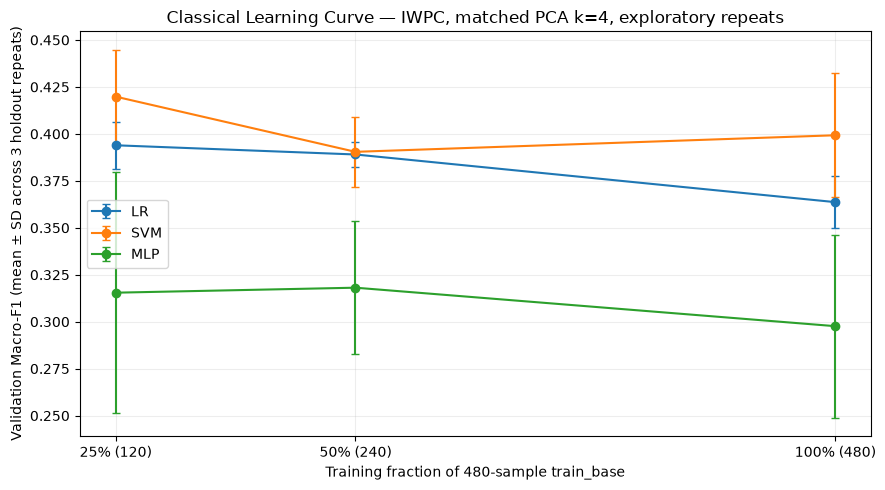

[PASS] 6 Classical Learning Curve artifacts saved in docs/results/
  - metrics: classical_learning_curve_k4_metrics.csv
  - predictions: classical_learning_curve_k4_predictions.csv
  - split_ids: classical_learning_curve_k4_split_ids.csv
  - summary: classical_learning_curve_k4_summary.csv
  - config: classical_learning_curve_k4_config.json
  - figure: classical_learning_curve_k4_macro_f1.png
[PASS] E03/E04/E05 Classical component complete; Quantum learning curves still pending


In [6]:
assert not any(path.exists() for path in FILES.values()), "Output exists: refuse overwrite"
OUT.mkdir(parents=True, exist_ok=True)

config = {
    "experiment_ids": ["E03", "E04", "E05"],
    "component": "Classical_only_LR_SVM_MLP",
    "status": "EXPLORATORY_POST_BASELINE_HOLDOUT_SEEDS",
    "important": "E03-E05 include quantum models too; this notebook completes only the Classical component",
    "data_pool": "locked_quantum_dev_pool_600_within_development",
    "heldout_final_test_used_for_fit_or_evaluation": False,
    "heldout_final_test_used_only_for_id_disjointness": True,
    "note_cv": "Three repeated stratified 480/120 holdouts, NOT the five locked E01 CV folds",
    "repeat_seeds": list(REPEAT_SEEDS),
    "seeds_selected_after_E01_baseline": True,
    "fraction_levels": list(FRACTIONS),
    "train_base_n": 480,
    "validation_n_per_repeat": 120,
    "nested_train_n": [120, 240, 480],
    "class_floor_smallest_train_and_validation": 10,
    "preprocessing": "train_subset_fitted_build_preprocessor_then_PCA_k4_then_MinMax_0_pi_clip",
    "target_encoding": {"mapping": CLASS_TO_INT, "reason": "MLP sklearn early_stopping compatibility; preserves alphabetical LabelBinarizer class order"},
    "model_hyperparameters_frozen_from_E01": {
        "LR": "LogisticRegression(max_iter=2000,random_state=42)",
        "SVM": "SVC(kernel='rbf',C=1.0,gamma='scale')",
        "MLP": "MLPClassifier(hidden_layer_sizes=(32,16),max_iter=500,early_stopping=True,n_iter_no_change=20,random_state=42)",
    },
    "metric_summary": "mean and sample SD (ddof=1) over three holdout repeats",
    "runtime": "preprocessing_seconds measured once per repeat/fraction, shared by three models; fit_seconds and predict_seconds are estimator-only",
    "feature_policy_temporal_evidence": "UNVERIFIED_research_only",
    "versions": {package: version(package) for package in ("numpy", "pandas", "scikit-learn", "PyYAML", "matplotlib")},
    "checksums": {name: sha256_file(path) for name, path in {
        "split_manifest": manifest_path,
        "feature_policy": policy_path,
        "experiment_matrix": ROOT / "docs/experiment_matrix.csv",
        "quantum_dev_pool": SPLITS / "quantum_dev_pool.csv",
    }.items()}
}

# Make plot in memory first, then export all files after checks.
fig, ax = plt.subplots(figsize=(9, 5))
for name in MODEL_NAMES:
    g = summary.loc[summary["model"] == name].sort_values("fraction")
    ax.errorbar(g["train_n"], g["macro_f1_mean"], yerr=g["macro_f1_sd"],
                marker="o", capsize=3, label=name)
ax.set_xticks([120, 240, 480], ["25% (120)", "50% (240)", "100% (480)"])
ax.set_xlabel("Training fraction of 480-sample train_base")
ax.set_ylabel("Validation Macro-F1 (mean ± SD across 3 holdout repeats)")
ax.set_title("Classical Learning Curve — IWPC, matched PCA k=4, exploratory repeats")
ax.grid(alpha=0.22)
ax.legend()
fig.tight_layout()

# All training and metrics validations have passed; create with exclusive mode.
for key, dataframe in (("metrics", metrics), ("predictions", predictions),
                       ("split_ids", pd.DataFrame(split_records)), ("summary", summary)):
    with FILES[key].open("x", newline="", encoding="utf-8-sig") as stream:
        dataframe.to_csv(stream, index=False)
with FILES["config"].open("x", encoding="utf-8") as stream:
    json.dump(config, stream, ensure_ascii=False, indent=2, allow_nan=False)
fig.savefig(FILES["figure"], dpi=170, bbox_inches="tight")
plt.show()

print("[PASS] 6 Classical Learning Curve artifacts saved in docs/results/")
for key, path in FILES.items():
    print(f"  - {key}: {path.name}")
print("[PASS] E03/E04/E05 Classical component complete; Quantum learning curves still pending")

## Checkpoint và phạm vi hoàn thành

**Đạt khi:** 3 repeats × 3 fractions × 3 models = **27 fits**; 3.240 predictions; 9 summary rows; tất cả class-count safeguards và kiểm tra ID PASS; 6 artifacts được ghi trong `docs/results/`.

**Chưa hoàn thành:** Learning Curve Quantum Kernel/VQC cho E03–E05, lựa chọn/freeze cấu hình cuối, final-test evaluation. Không chỉnh lại 5 folds GĐ4. Không chọn learning-curve seed tốt nhất, không thay đổi model hyperparameters sau khi nhìn thấy learning-curve scores.

**Dọn file:** Notebook này **giữ** vì là runner chính thức có thể tái lập. Không cần tạo file `.py` trong `scripts/`. Khi kết quả đã lưu, không xóa `split_ids.csv`, `metrics.csv`, `predictions.csv` hay config; chúng cung cấp bằng chứng của thiết kế holdout.